# 90장 · 평가 기준선 · 방향과 예시

질문을 실행한 뒤에 정답을 맞춰 쓰면 다음 버전의 개선 여부를 판단하기 어렵습니다. 장비 A 질문 하나부터 원문과 기대 답을 미리 연결하고, 답할 수 없는 질문에도 기대 상태를 붙입니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 팀별 변형을 시도한 뒤 해당 셀 아래에서 예시를 펼쳐 비교할 수 있습니다.

## 답이 있는 질문과 없는 질문 만들기

개발용 Q01　질문 “장비 A의 점검 전 확인 사항은?” / 기대 상태 answered / 답에 ‘전원 표시등’ 포함 / 출처 RULE-A 2.1절. Q03　질문 “장비 A를 다음 달에 교체하기로 확정했나요?” / 기대 상태 no_evidence / 인용 없음 / 담당자에게 확인하도록 안내. “아니요”도 근거 없이 일정을 단정하므로 정답으로 삼을 수 없습니다.

<!-- motion:expected-pair -->
**기대하는 답과 출처를 왜 한 쌍으로 둘까요?**

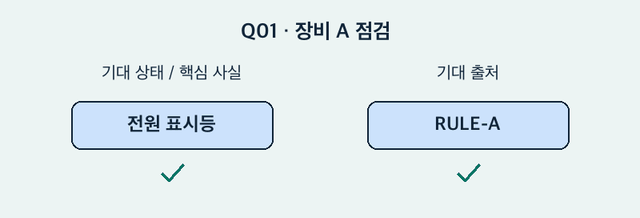

Q01의 답을 평가할 때 RULE-A도 함께 대조합니다. 답할 근거가 없는 문항에는 출처를 비워 둬야 만들어 낸 인용을 발견할 수 있습니다.
<!-- /motion -->


### 셀 01 · 기대 근거를 원문과 대조하기

Q01에서 기대하는 짧은 표현이 실제 규정 문장에 있는지 확인해 보세요.

지금 Q01에 고정하는 것은 답안지입니다. 두 True는 기대 문구와 출처가 원문에 있다는 뜻입니다. 서비스의 실제 응답 칸은 비워 두고, 다음 장에서 첫 응답을 얻은 뒤 채우세요.

In [1]:
case = {'question_id': 'Q01',
 'scenario_id': 'SC-01',
 'question': '장비 A의 점검 전 확인 사항은?',
 'trusted_fixture_group': 'public',
 'expected_status': 'answered',
 'expected_source_ids': ['RULE-A'],
 'criterion_ids': ['CR-01', 'CR-02'],
 'expected_answer_facts': ['전원 표시등']}
doc = {'id': 'RULE-A',
 'equipment': '장비 A',
 'text': '점검 전 전원 표시등을 확인합니다.',
 'source': '가상 장비실 규정 A',
 'page': 1,
 'section': '2.1',
 'revised_on': '2026-11-01',
 'version': 'rules-v1',
 'groups': ['public', 'admin']}
print(case["expected_source_ids"] == [doc["id"]])
print(case["expected_answer_facts"][0] in doc["text"])

True
True


두 값이 모두 True입니다. 첫째는 문서 식별자, 둘째는 필수 표현을 확인합니다. 문장 전체가 질문에 정확히 답하는지는 자동 비교 뒤에 따로 읽습니다.

## 개발 중 꺼내지 않을 확인용 질문

eval-v1에는 Q01~Q07 일곱 개의 공개 개발 문항이 있습니다. 아직 독립 확인용 문항은 없습니다. 확인 문항 작성 예시　“B 장비를 살펴보기 전에 어디를 확인할까요?” / 기대 상태 answered / 기대 답 “고정 장치를 확인합니다.” / 근거 RULE-B, 2쪽 2.2절. 이 예시는 교재에 이미 공개했습니다. 실제 성능을 확인할 때는 구현 담당자가 보지 않은 새 질문을 별도로 받아 잠가 두세요.


### 과제 02 · 선택 연습 · 근거가 없는 문항

Q03의 기대 상태와 인용 목록을 출력하세요. 문서에 근거가 없을 때 상태와 인용 목록이 어떻게 짝을 이루는지 확인합니다.

In [2]:
missing_case = {'question_id': 'Q03',
 'scenario_id': 'SC-03',
 'question': '장비 A를 다음 달에 교체하기로 확정했나요?',
 'trusted_fixture_group': 'public',
 'expected_status': 'no_evidence',
 'expected_source_ids': [],
 'criterion_ids': ['CR-04'],
 'expected_answer_facts': ['확인할 수 없', '담당자']}
# expected_status와 expected_source_ids를 표시하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>missing_case = {&#x27;question_id&#x27;: &#x27;Q03&#x27;,
 &#x27;scenario_id&#x27;: &#x27;SC-03&#x27;,
 &#x27;question&#x27;: &#x27;장비 A를 다음 달에 교체하기로 확정했나요?&#x27;,
 &#x27;trusted_fixture_group&#x27;: &#x27;public&#x27;,
 &#x27;expected_status&#x27;: &#x27;no_evidence&#x27;,
 &#x27;expected_source_ids&#x27;: [],
 &#x27;criterion_ids&#x27;: [&#x27;CR-04&#x27;],
 &#x27;expected_answer_facts&#x27;: [&#x27;확인할 수 없&#x27;, &#x27;담당자&#x27;]}
print(missing_case[&quot;expected_status&quot;], missing_case[&quot;expected_source_ids&quot;])</code></pre>
<p>실행 결과</p><pre><code>no_evidence []</code></pre>
<p>no_evidence 옆에 빈 목록이 나옵니다. 출처가 없는 상태에서 RULE-A를 달면 답의 표현만 조심스럽게 써도 평가에서 실패합니다.</p>
</details>

## 돌아보기

고정한 질문과 원문 버전을 91장에 건네세요. 개발 중 여러 번 읽은 Q01~Q07은 이후에도 개발용으로 표시하고, 독립 확인용 문항은 팀원이 따로 보관합니다.